In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.layers import BatchNormalization

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
    classification_report
)

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
data = pd.read_csv("https://raw.githubusercontent.com/brina948/Deep-Learning/refs/heads/main/datasets/cross-sectional/bank-additional%5B1%5D.csv.",sep=";")
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# **Data Pre-Processing**

**Informasi Data**

In [ ]:
data.info()
display(data.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Missing Value**

In [ ]:
missing_count = data.isna().sum()
missing_percent = (data.isna().mean() * 100).round(2)

missing_count

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


**Duplikat**

In [ ]:
print("Jumlah baris duplikat:", data.duplicated().sum())

Jumlah baris duplikat: 12


**Imbalance Data**

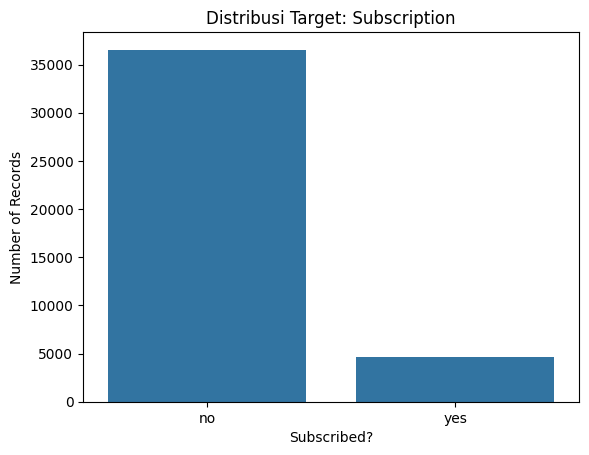

In [ ]:
sns.countplot(data=data, x="y")
plt.title("Distribusi Target: Subscription")
plt.xlabel("Subscribed?")
plt.ylabel("Number of Records")
plt.show()

**Spli Training dan Testing**

In [ ]:
data_model = data.drop(columns=["duration"],errors="ignore").copy()

X = data_model.drop(columns=["y"])
y = data_model["y"].map({"no": 0,"yes": 1})

In [ ]:
# Tahap 1: 60% training dan 40% data sementara
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.40,random_state=42, stratify=y)

# Tahap 2: data sementara dibagi sama rata
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42,stratify=y_temp)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (24712, 19) (24712,)
Validation: (8238, 19) (8238,)
Testing: (8238, 19) (8238,)


**Pisahkan fitur numerik dan kategorikal**

In [ ]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)

Fitur numerik: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Fitur kategorikal: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


**Tangani missing value numerik**

In [ ]:
# Hitung median dari training saja
median_values = X_train[numeric_features].median()

# Isi missing value
X_train[numeric_features] = (X_train[numeric_features].fillna(median_values))
X_val[numeric_features] = (X_val[numeric_features].fillna(median_values))
X_test[numeric_features] = (X_test[numeric_features].fillna(median_values))

**Standardisasi fitur numerik**

In [ ]:
scaler = StandardScaler()

# Fit dan transform hanya pada training
X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])

# Validation dan testing hanya ditransformasi
X_val[numeric_features] = scaler.transform(X_val[numeric_features])
X_test[numeric_features] = scaler.transform(X_test[numeric_features])

**Tangani missing value kategorikal**

In [ ]:
# Hitung modus dari training saja
mode_values = X_train[categorical_features].mode().iloc[0]

X_train[categorical_features] = (X_train[categorical_features].fillna(mode_values))
X_val[categorical_features] = (X_val[categorical_features].fillna(mode_values))
X_test[categorical_features] = (X_test[categorical_features].fillna(mode_values))

**One-Hot Encoding**

In [ ]:
encoder = OneHotEncoder(handle_unknown="ignore",sparse_output=False)

# Fit dan transform training
X_train_cat = encoder.fit_transform(X_train[categorical_features])

# Transform validation dan testing
X_val_cat = encoder.transform(X_val[categorical_features])
X_test_cat = encoder.transform(X_test[categorical_features])

**Gabungkan fitur numerik dan kategorikal**

In [ ]:
# Ambil fitur numerik
X_train_num = X_train[numeric_features].to_numpy()
X_val_num = X_val[numeric_features].to_numpy()
X_test_num = X_test[numeric_features].to_numpy()

# Gabungkan fitur numerik dan kategorikal
X_train_processed = np.concatenate([X_train_num, X_train_cat], axis=1).astype("float32")
X_val_processed = np.concatenate([X_val_num, X_val_cat], axis=1).astype("float32")
X_test_processed = np.concatenate([X_test_num, X_test_cat], axis=1).astype("float32")

# Target
y_train_array = y_train.to_numpy(dtype="float32")
y_val_array = y_val.to_numpy(dtype="float32")
y_test_array = y_test.to_numpy(dtype="float32")

# Jumlah node input
n_features = X_train_processed.shape[1]

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)
print("Jumlah node input:", n_features)

Training: (24712, 62)
Validation: (8238, 62)
Testing: (8238, 62)
Jumlah node input: 62


# **Modelling**

**Membangun model baseline**

In [ ]:
baseline_model = Sequential([
    Input(shape=(n_features,)),
    Dense(64, activation="relu"),
    BatchNormalization(),
    Dense(32, activation="relu"),
    BatchNormalization(),
    Dense(1, activation="sigmoid")
])

# optimizer=tf.keras.optimizers.Adam(learning_rate=0.01)
# optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.01)
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,529 (25.50 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 192 (768.00 B)

**Training model baseline**

In [ ]:
history = baseline_model.fit(
    X_train_processed,
    y_train_array,
    validation_data=(
        X_val_processed,
        y_val_array
    ),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8903 - loss: 0.3028 - val_accuracy: 0.8911 - val_loss: 0.2830
Epoch 2/50
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8971 - loss: 0.2855 - val_accuracy: 0.8963 - val_loss: 0.2755
Epoch 3/50
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8978 - loss: 0.2831 - val_accuracy: 0.8958 - val_loss: 0.2747
Epoch 4/50
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8989 - loss: 0.2806 - val_accuracy: 0.8972 - val_loss: 0.2760
Epoch 5/50
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8993 - loss: 0.2794 - val_accuracy: 0.8978 - val_loss: 0.2772
Epoch 6/50
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9001 - loss: 0.2775 - val_accuracy: 0.8963 - val_loss: 0.2798
Epoch 7/50
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9009 - loss: 0.2760 - val_accuracy: 0.8967 - val_loss: 0.2777
Epoch 8/50
773/773 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9009 - loss: 0.2742 - val_accuracy: 0.

# **Evaluasi**

**Visualisasi training dan validation loss**

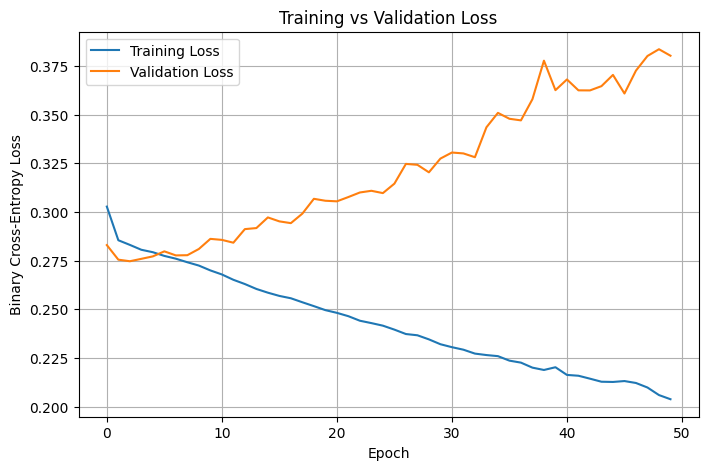

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

**Evaluation pada data testing**

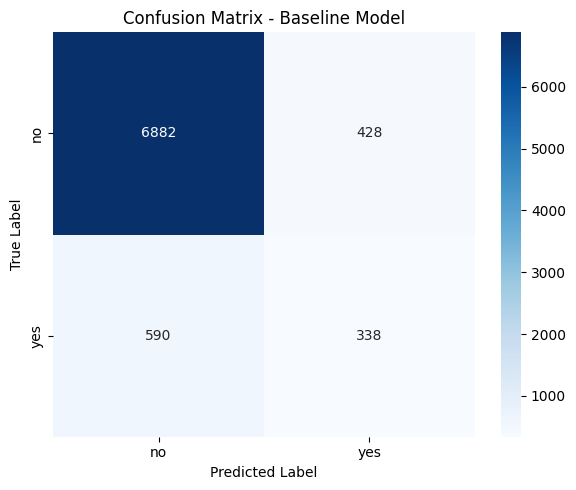

In [ ]:
# Prediksi probabilitas kelas positif
y_test_prob = baseline_model.predict(X_test_processed, verbose=0).ravel()

# Konversi probabilitas menjadi label kelas
y_test_pred = (y_test_prob >= 0.5).astype(int)

# Membuat confusion matrix
cm = confusion_matrix(y_test_array, y_test_pred)

# Visualisasi heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["no", "yes"], yticklabels=["no", "yes"])

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Baseline Model")
plt.tight_layout()
plt.show()

In [ ]:
print(classification_report(y_test_array.astype(int), y_test_pred, labels=[0, 1],
                            target_names=["No", "Yes"], digits=4, zero_division=0))

              precision    recall  f1-score   support

          No     0.9210    0.9415    0.9311      7310
         Yes     0.4413    0.3642    0.3991       928

    accuracy                         0.8764      8238
   macro avg     0.6811    0.6528    0.6651      8238
weighted avg     0.8670    0.8764    0.8712      8238

